# Retos del workshop RAG · teoría con simulación y retos C1, C4, C6

**Autor:** Jerónimo Zapata Cuadros (`JCuAdrox`) · SI3003, EAFIT

Construido a partir de `04_challenges_starter.ipynb` de la plantilla. Contiene:

| Sección | Qué hace | ¿Necesita API? |
|---|---|---|
| T1 | Simulación de la asignación de capas de HNSW | no |
| Escala del umbral | Experimento con vectores conocidos: ¿`score_threshold` compara contra el coseno? | no |
| C1 | FAISS `IndexFlatL2` vs `IndexHNSWFlat` (recall, latencia, construcción) | no |
| C4 | `eval/preguntas.csv`: verificación de palabras clave en los PDFs + hit@3/hit@5 | la verificación no; hit@k sí |
| C6 | `QdrantClient(path=...)`: indexar una vez y reabrir en un proceso nuevo | sí |

Las celdas que necesitan `NVIDIA_API_KEY` la buscan en el entorno y, si no está, lo dicen sin fallar.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q faiss-cpu matplotlib "markitdown[pdf]" langchain-nvidia-ai-endpoints langchain-qdrant qdrant-client langchain-text-splitters

In [2]:
import os
import time
import json
import concurrent.futures
from pathlib import Path
from typing import List, Dict

import numpy as np
import matplotlib
import matplotlib.pyplot as plt


def find_repo_root() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "RESPUESTAS.md").exists():
            return base
    return Path.cwd()


ROOT = find_repo_root()
EVIDENCIAS = ROOT / "evidencias"
EVIDENCIAS.mkdir(exist_ok=True)

NVIDIA_API_KEY = None
try:
    from google.colab import userdata
    NVIDIA_API_KEY = userdata.get("NVIDIA_API_KEY")
except Exception:
    NVIDIA_API_KEY = os.getenv("NVIDIA_API_KEY")
HAS_KEY = bool(NVIDIA_API_KEY)
if HAS_KEY:
    os.environ["NVIDIA_API_KEY"] = NVIDIA_API_KEY
GENERATION_MODEL = "nvidia/nemotron-3.5-lightning-30b-a3b"
EMBEDDING_MODEL = "nvidia/llama-nemotron-embed-vl-1b-v2"
print("raíz:", ROOT.name, "| ¿NVIDIA_API_KEY disponible?", HAS_KEY)

raíz: Inteligencia_Artificial | ¿NVIDIA_API_KEY disponible? False


## T1 · ¿Cuántos nodos viven en cada capa?

Capa de cada nodo: $l = \lfloor -\ln(U)\cdot m_L \rfloor$ con $U\sim\mathcal U(0,1)$ y $m_L = 1/\ln M$. Entonces $P(l \ge k) = P(U \le M^{-k}) = M^{-k}$.

Con $M = 16$ y $N = 10^6$: valor esperado en capas $\ge k$ = $N\cdot 16^{-k}$.

In [3]:
M, N = 16, 1_000_000
mL = 1 / np.log(M)
expected = {k: N * M ** (-k) for k in (1, 2, 3, 4)}

rng = np.random.default_rng(2026)
U = 1.0 - rng.random(N)                      # U en (0, 1]: evita log(0)
levels = np.floor(-np.log(U) * mL).astype(int)

print(f"mL = 1/ln(16) = {mL:.4f}\n")
print("| capa ≥ k | esperado N·16^-k | simulado (semilla 2026) | error relativo |")
print("|---|---|---|---|")
for k, e in expected.items():
    s = int((levels >= k).sum())
    print(f"| ≥{k} | {e:,.1f} | {s:,} | {(s - e) / e:+.1%} |")
print(f"\ncapa máxima observada: {levels.max()} | nodos solo en la capa 0: {(levels == 0).mean():.2%}")

# Variabilidad: 20 repeticiones
reps = np.array([[(np.floor(-np.log(1.0 - r.random(N)) * mL) >= k).sum() for k in (1, 2, 3)]
                 for r in (np.random.default_rng(s) for s in range(20))])
for i, k in enumerate((1, 2, 3)):
    print(f"capa ≥{k}: media de 20 corridas = {reps[:, i].mean():,.1f} ± {reps[:, i].std():.1f}")

mL = 1/ln(16) = 0.3607

| capa ≥ k | esperado N·16^-k | simulado (semilla 2026) | error relativo |
|---|---|---|---|
| ≥1 | 62,500.0 | 62,512 | +0.0% |
| ≥2 | 3,906.2 | 3,977 | +1.8% |
| ≥3 | 244.1 | 254 | +4.0% |
| ≥4 | 15.3 | 19 | +24.5% |

capa máxima observada: 5 | nodos solo en la capa 0: 93.75%


capa ≥1: media de 20 corridas = 62,587.1 ± 270.1
capa ≥2: media de 20 corridas = 3,892.8 ± 80.2
capa ≥3: media de 20 corridas = 244.6 ± 17.1


## Experimento sin API: ¿en qué escala compara `score_threshold`?

Se usan embeddings hechos a mano con cosenos conocidos frente a la consulta (1, 0.6, 0, −0.5, −1) y se compara lo que devuelve Qdrant con lo que filtra el retriever `similarity_score_threshold`.

In [4]:
from langchain_core.embeddings import Embeddings
from langchain_core.documents import Document
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, VectorParams

ANGLES = {"cos=+1.0": 1.0, "cos=+0.6": 0.6, "cos=0.0": 0.0, "cos=-0.5": -0.5, "cos=-1.0": -1.0}


class KnownEmbeddings(Embeddings):
    """Consulta = (1, 0); cada documento forma el ángulo cuyo coseno indica su texto."""
    def embed_documents(self, texts):
        # textos desconocidos (p. ej. la validación "dummy_text" de QdrantVectorStore) → misma dirección que la consulta
        return [[ANGLES.get(t, 1.0), float(np.sqrt(1 - ANGLES.get(t, 1.0) ** 2))] for t in texts]

    def embed_query(self, text):
        return [1.0, 0.0]


client = QdrantClient(":memory:")
client.create_collection("escala", vectors_config=VectorParams(size=2, distance=Distance.COSINE))
store = QdrantVectorStore(client=client, collection_name="escala", embedding=KnownEmbeddings())
store.add_documents([Document(page_content=t) for t in ANGLES])  # 5 documentos

print("| documento | similarity_search_with_score | similarity_search_with_relevance_scores |")
print("|---|---|---|")
rel = dict((d.page_content, s) for d, s in store.similarity_search_with_relevance_scores("q", k=5))
for d, s in store.similarity_search_with_score("q", k=5):
    print(f"| {d.page_content} | {s:+.3f} | {rel[d.page_content]:.3f} |")

print()
for thr in (0.15, 0.25, 0.3, 0.40, 0.8):
    retr = store.as_retriever(search_type="similarity_score_threshold", search_kwargs={"k": 5, "score_threshold": thr})
    print(f"score_threshold={thr:<4} → devuelve {[d.page_content for d in retr.invoke('q')]}")

| documento | similarity_search_with_score | similarity_search_with_relevance_scores |
|---|---|---|
| cos=+1.0 | +1.000 | 1.000 |
| cos=+0.6 | +0.600 | 0.800 |
| cos=0.0 | +0.000 | 0.500 |
| cos=-0.5 | -0.500 | 0.250 |
| cos=-1.0 | -1.000 | 0.000 |

score_threshold=0.15 → devuelve ['cos=+1.0', 'cos=+0.6', 'cos=0.0', 'cos=-0.5']
score_threshold=0.25 → devuelve ['cos=+1.0', 'cos=+0.6', 'cos=0.0', 'cos=-0.5']
score_threshold=0.3  → devuelve ['cos=+1.0', 'cos=+0.6', 'cos=0.0']
score_threshold=0.4  → devuelve ['cos=+1.0', 'cos=+0.6', 'cos=0.0']
score_threshold=0.8  → devuelve ['cos=+1.0', 'cos=+0.6']


## C1 · HNSW contra fuerza bruta con FAISS

Línea base del starter (n = 20 000, d = 64, 200 consultas, k = 10, efConstruction = 100), con la grilla completa M ∈ {8, 16, 32} × efSearch ∈ {10, 16, 32, 64, 128, 256}. La latencia se mide con las 200 consultas en un solo lote (como en el starter) y se divide entre 200.

In [5]:
import faiss

print("FAISS", faiss.__version__, "| hilos OpenMP:", faiss.omp_get_max_threads())
d, nq, k = 64, 200, 10
EF_VALUES = (10, 16, 32, 64, 128, 256)


def recall_at_k(I, I_true):
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I, I_true)]))


def timed_search(index, xq, k, repeats=3):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); _, I = index.search(xq, k); best = min(best, time.perf_counter() - t0)
    return I, best / len(xq) * 1000


def run_experiment(xb, xq, Ms=(8, 16, 32), efs=EF_VALUES, ef_construction=100):
    flat = faiss.IndexFlatL2(xb.shape[1])
    t0 = time.perf_counter(); flat.add(xb); flat_build = time.perf_counter() - t0
    I_true, t_flat = timed_search(flat, xq, k)
    rows = []
    for M in Ms:
        index = faiss.IndexHNSWFlat(xb.shape[1], M)
        index.hnsw.efConstruction = ef_construction
        t0 = time.perf_counter(); index.add(xb); build_s = time.perf_counter() - t0
        for ef in efs:
            index.hnsw.efSearch = ef
            I, ms = timed_search(index, xq, k)
            rows.append(dict(n=len(xb), M=M, ef=ef, recall=recall_at_k(I, I_true), ms=ms, build_s=build_s))
    return dict(flat_ms=t_flat, flat_build_s=flat_build, rows=rows)


rng = np.random.default_rng(42)
xb = rng.random((20_000, d), dtype="float32")
xq = rng.random((nq, d), dtype="float32")
res20k = run_experiment(xb, xq)

print(f"exacto (IndexFlatL2): {res20k['flat_ms']:.3f} ms/consulta\n")
print("| M | efSearch | recall@10 | ms/consulta | construcción (s) | más rápido que exacto |")
print("|---|---|---|---|---|---|")
for r in res20k["rows"]:
    print(f"| {r['M']} | {r['ef']} | {r['recall']:.3f} | {r['ms']:.4f} | {r['build_s']:.2f} | {'sí' if r['ms'] < res20k['flat_ms'] else 'no'} |")

FAISS 1.15.1 | hilos OpenMP: 12


exacto (IndexFlatL2): 0.030 ms/consulta

| M | efSearch | recall@10 | ms/consulta | construcción (s) | más rápido que exacto |
|---|---|---|---|---|---|
| 8 | 10 | 0.168 | 0.0013 | 0.21 | sí |
| 8 | 16 | 0.242 | 0.0015 | 0.21 | sí |
| 8 | 32 | 0.355 | 0.0030 | 0.21 | sí |
| 8 | 64 | 0.510 | 0.0057 | 0.21 | sí |
| 8 | 128 | 0.683 | 0.0126 | 0.21 | sí |
| 8 | 256 | 0.819 | 0.0266 | 0.21 | sí |
| 16 | 10 | 0.329 | 0.0018 | 0.27 | sí |
| 16 | 16 | 0.425 | 0.0022 | 0.27 | sí |
| 16 | 32 | 0.599 | 0.0037 | 0.27 | sí |
| 16 | 64 | 0.770 | 0.0069 | 0.27 | sí |
| 16 | 128 | 0.905 | 0.0145 | 0.27 | sí |
| 16 | 256 | 0.971 | 0.0327 | 0.27 | no |
| 32 | 10 | 0.468 | 0.0026 | 0.32 | sí |
| 32 | 16 | 0.579 | 0.0033 | 0.32 | sí |
| 32 | 32 | 0.761 | 0.0055 | 0.32 | sí |
| 32 | 64 | 0.909 | 0.0099 | 0.32 | sí |
| 32 | 128 | 0.983 | 0.0195 | 0.32 | sí |
| 32 | 256 | 0.998 | 0.0417 | 0.32 | no |


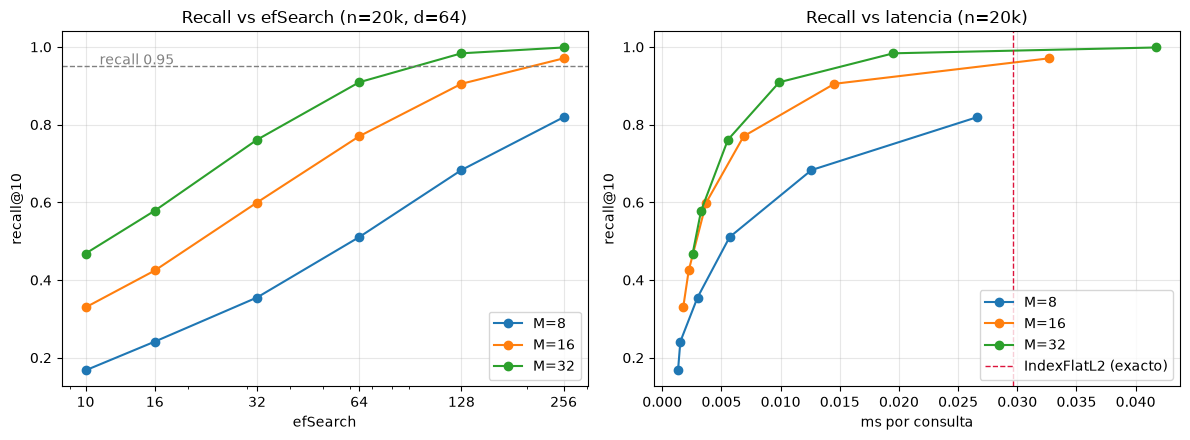

efSearch mínimo con recall ≥ 0.95 y M=16 (n=20k): 256 (recall 0.971, 0.0327 ms)


In [6]:
# TODO 1: recall vs efSearch (una curva por M) y recall vs latencia
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for M in (8, 16, 32):
    rows = [r for r in res20k["rows"] if r["M"] == M]
    axes[0].plot([r["ef"] for r in rows], [r["recall"] for r in rows], marker="o", label=f"M={M}")
    axes[1].plot([r["ms"] for r in rows], [r["recall"] for r in rows], marker="o", label=f"M={M}")
axes[0].axhline(0.95, ls="--", c="gray", lw=1); axes[0].text(11, 0.955, "recall 0.95", color="gray")
axes[0].set(xscale="log", xlabel="efSearch", ylabel="recall@10", title="Recall vs efSearch (n=20k, d=64)")
axes[0].set_xticks(EF_VALUES, [str(e) for e in EF_VALUES])
axes[1].axvline(res20k["flat_ms"], ls="--", c="crimson", lw=1, label="IndexFlatL2 (exacto)")
axes[1].set(xlabel="ms por consulta", ylabel="recall@10", title="Recall vs latencia (n=20k)")
for ax in axes:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(EVIDENCIAS / "C1_recall_vs_ef_y_latencia.png", dpi=130)
plt.show()

m16 = [r for r in res20k["rows"] if r["M"] == 16]
first = next((r for r in m16 if r["recall"] >= 0.95), None)
print("efSearch mínimo con recall ≥ 0.95 y M=16 (n=20k):",
      f"{first['ef']} (recall {first['recall']:.3f}, {first['ms']:.4f} ms)" if first else "ninguno en la grilla")

### TODO 2 · ¿Desde qué n HNSW supera al exacto?

Se repite con n = 100 000 y 500 000. Para que quepa en tiempo se usa M = 16 (el valor central) con la grilla de efSearch ampliada a 512 y 1024, porque con n grande ef=256 ya no alcanza recall 0.95.

In [7]:
scaling = {20_000: res20k}
for n in (100_000, 500_000):
    xb_n = np.random.default_rng(42).random((n, d), dtype="float32")
    t0 = time.perf_counter()
    scaling[n] = run_experiment(xb_n, xq, Ms=(16,), efs=EF_VALUES + (512, 1024))
    print(f"n={n:,}: experimento en {time.perf_counter() - t0:.0f}s")
res20k["rows"] += run_experiment(xb, xq, Ms=(16,), efs=(512, 1024))["rows"]

print("\n| n | exacto ms/q | HNSW M=16 build (s) | ef | recall@10 | HNSW ms/q | aceleración |")
print("|---|---|---|---|---|---|---|")
for n, res in scaling.items():
    for r in [r for r in res["rows"] if r["M"] == 16]:
        print(f"| {n:,} | {res['flat_ms']:.3f} | {r['build_s']:.1f} | {r['ef']} | {r['recall']:.3f} | {r['ms']:.4f} | {res['flat_ms'] / r['ms']:.1f}× |")

n=100,000: experimento en 3s


n=500,000: experimento en 16s



| n | exacto ms/q | HNSW M=16 build (s) | ef | recall@10 | HNSW ms/q | aceleración |
|---|---|---|---|---|---|---|
| 20,000 | 0.030 | 0.3 | 10 | 0.329 | 0.0018 | 16.8× |
| 20,000 | 0.030 | 0.3 | 16 | 0.425 | 0.0022 | 13.3× |
| 20,000 | 0.030 | 0.3 | 32 | 0.599 | 0.0037 | 8.0× |
| 20,000 | 0.030 | 0.3 | 64 | 0.770 | 0.0069 | 4.3× |
| 20,000 | 0.030 | 0.3 | 128 | 0.905 | 0.0145 | 2.0× |
| 20,000 | 0.030 | 0.3 | 256 | 0.971 | 0.0327 | 0.9× |
| 20,000 | 0.030 | 0.3 | 512 | 0.993 | 0.0785 | 0.4× |
| 20,000 | 0.030 | 0.3 | 1024 | 0.997 | 0.2160 | 0.1× |
| 100,000 | 0.198 | 2.1 | 10 | 0.527 | 0.0026 | 76.7× |
| 100,000 | 0.198 | 2.1 | 16 | 0.586 | 0.0037 | 54.0× |
| 100,000 | 0.198 | 2.1 | 32 | 0.671 | 0.0063 | 31.4× |
| 100,000 | 0.198 | 2.1 | 64 | 0.746 | 0.0114 | 17.3× |
| 100,000 | 0.198 | 2.1 | 128 | 0.826 | 0.0225 | 8.8× |
| 100,000 | 0.198 | 2.1 | 256 | 0.907 | 0.0503 | 3.9× |
| 100,000 | 0.198 | 2.1 | 512 | 0.957 | 0.1123 | 1.8× |
| 100,000 | 0.198 | 2.1 | 1024 | 0.981 | 0.2836 | 0.7

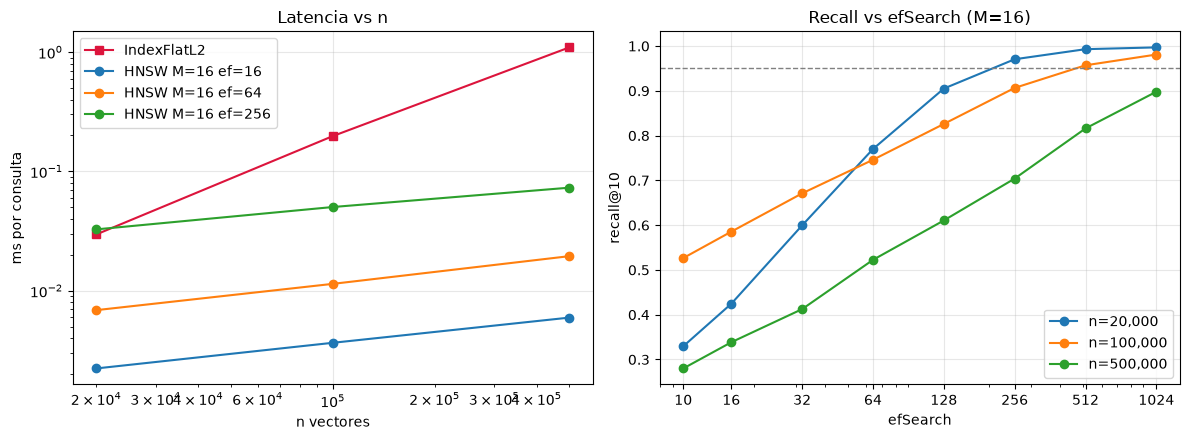

Primer efSearch con recall ≥ 0.95 (M=16) y su velocidad frente al exacto:
  n= 20,000: ef=256, recall=0.971, 0.0327 ms vs 0.0296 ms exacto → 0.9×
  n=100,000: ef=512, recall=0.957, 0.1123 ms vs 0.1976 ms exacto → 1.8×
  n=500,000: no se alcanza con ef ≤ 1024
CSV guardado en evidencias/C1_resultados.csv


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ns = list(scaling)
axes[0].plot(ns, [scaling[n]["flat_ms"] for n in ns], marker="s", c="crimson", label="IndexFlatL2")
for ef in (16, 64, 256):
    axes[0].plot(ns, [next(r["ms"] for r in scaling[n]["rows"] if r["M"] == 16 and r["ef"] == ef) for n in ns],
                 marker="o", label=f"HNSW M=16 ef={ef}")
axes[0].set(xscale="log", yscale="log", xlabel="n vectores", ylabel="ms por consulta", title="Latencia vs n")
for n in ns:
    rows = [r for r in scaling[n]["rows"] if r["M"] == 16]
    axes[1].plot([r["ef"] for r in rows], [r["recall"] for r in rows], marker="o", label=f"n={n:,}")
axes[1].set(xscale="log", xlabel="efSearch", ylabel="recall@10", title="Recall vs efSearch (M=16)")
axes[1].axhline(0.95, ls="--", c="gray", lw=1)
axes[1].set_xticks(EF_VALUES + (512, 1024), [str(e) for e in EF_VALUES + (512, 1024)])
for ax in axes:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(EVIDENCIAS / "C1_escalamiento_n.png", dpi=130)
plt.show()

print("Primer efSearch con recall ≥ 0.95 (M=16) y su velocidad frente al exacto:")
for n, res in scaling.items():
    r = next((r for r in sorted(res["rows"], key=lambda r: r["ef"]) if r["M"] == 16 and r["recall"] >= 0.95), None)
    print(f"  n={n:>7,}: " + (f"ef={r['ef']}, recall={r['recall']:.3f}, {r['ms']:.4f} ms vs {res['flat_ms']:.4f} ms exacto → {res['flat_ms'] / r['ms']:.1f}×" if r else "no se alcanza con ef ≤ 1024"))

import csv
with open(EVIDENCIAS / "C1_resultados.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["n", "M", "efSearch", "recall@10", "hnsw_ms_por_consulta", "construccion_s", "exacto_ms_por_consulta"])
    for n, res in scaling.items():
        for r in res["rows"]:
            w.writerow([n, r["M"], r["ef"], round(r["recall"], 4), round(r["ms"], 5), round(r["build_s"], 2), round(res["flat_ms"], 5)])
print("CSV guardado en evidencias/C1_resultados.csv")

### ¿Por qué los datos aleatorios son un caso difícil?

Se mide el *contraste relativo* (distancia al más lejano / distancia al más cercano) y se repite HNSW sobre datos con estructura (50 clústeres gaussianos) del mismo tamaño.

In [9]:
def contrast(xb, xq):
    D = ((xq[:50, None, :] - xb[None, :, :]) ** 2).sum(-1) ** 0.5
    return float(np.mean(D.max(1) / D.min(1)))


rng = np.random.default_rng(7)
centers = rng.random((50, d), dtype="float32")
labels = rng.integers(0, 50, 20_000)
xb_cl = (centers[labels] + rng.normal(0, 0.05, (20_000, d))).astype("float32")
xq_cl = (centers[rng.integers(0, 50, nq)] + rng.normal(0, 0.05, (nq, d))).astype("float32")

print(f"contraste max/min — uniforme: {contrast(xb, xq):.2f} | con clústeres: {contrast(xb_cl, xq_cl):.2f}")
res_cl = run_experiment(xb_cl, xq_cl, Ms=(16,))
print("\n| efSearch | recall uniforme (M=16) | recall clústeres (M=16) |")
print("|---|---|---|")
for a, b in zip([r for r in res20k["rows"] if r["M"] == 16], res_cl["rows"]):
    print(f"| {a['ef']} | {a['recall']:.3f} | {b['recall']:.3f} |")

contraste max/min — uniforme: 1.78 | con clústeres: 9.03

| efSearch | recall uniforme (M=16) | recall clústeres (M=16) |
|---|---|---|
| 10 | 0.329 | 0.857 |
| 16 | 0.425 | 0.933 |
| 32 | 0.599 | 0.984 |
| 64 | 0.770 | 1.000 |
| 128 | 0.905 | 1.000 |
| 256 | 0.971 | 1.000 |


## C4 · Evaluación automática de la recuperación

`eval/preguntas.csv` tiene 10 preguntas propias (5 por paper) con `fuente_esperada` y `palabra_clave`. Como MarkItDown pega palabras en muchas líneas, las palabras clave son tokens cortos (cifras o términos sin espacios) y **se verifica primero** que cada una aparece en el texto extraído del paper correcto.

In [10]:
import csv
import requests
from markitdown import MarkItDown


def cargar_preguntas(ruta=ROOT / "eval" / "preguntas.csv"):
    with open(ruta, encoding="utf-8") as f:
        return list(csv.DictReader(f))


DOCS_DIR = ROOT / "papers"
DOCS_DIR.mkdir(exist_ok=True)
COURSE_RAW = "https://raw.githubusercontent.com/EAFIT-IA/si3003-artificial-intelligence/main/notebooks/lecture10/papers/"
PAPERS = {"attention_paper.pdf": "https://arxiv.org/pdf/1706.03762", "rag_paper.pdf": "https://arxiv.org/pdf/2005.11401"}
TITLES = {"attention_paper.pdf": "Attention Is All You Need", "rag_paper.pdf": "Retrieval-Augmented Generation"}
for name, url in PAPERS.items():
    path = DOCS_DIR / name
    if not (path.exists() and path.stat().st_size > 10_000):
        for candidate in (url, COURSE_RAW + name):
            try:
                r = requests.get(candidate, timeout=90); r.raise_for_status()
                if r.content.startswith(b"%PDF"):
                    path.write_bytes(r.content); break
            except Exception as error:
                print("descarga falló:", candidate, error)

converter = MarkItDown(enable_plugins=False)
PAPER_TEXT = {name: converter.convert(str(DOCS_DIR / name)).text_content for name in PAPERS}
filas = cargar_preguntas()

print("| id | palabra_clave | fuente_esperada | apariciones en el paper correcto | apariciones en el otro |")
print("|---|---|---|---|---|")
for r in filas:
    kw = r["palabra_clave"].lower()
    own = PAPER_TEXT[r["fuente_esperada"]].lower().count(kw)
    other = sum(t.lower().count(kw) for n, t in PAPER_TEXT.items() if n != r["fuente_esperada"])
    print(f"| {r['id']} | {r['palabra_clave']} | {r['fuente_esperada']} | {own} | {other} |")
assert all(r["palabra_clave"].lower() in PAPER_TEXT[r["fuente_esperada"]].lower() for r in filas), "falta una palabra clave"
print(f"\n✅ Las {len(filas)} palabras clave aparecen en el texto extraído de su paper.")

| id | palabra_clave | fuente_esperada | apariciones en el paper correcto | apariciones en el otro |
|---|---|---|---|---|
| 1 | 28.4 | attention_paper.pdf | 3 | 0 |
| 2 | 4000 | attention_paper.pdf | 1 | 0 |
| 3 | P100 | attention_paper.pdf | 4 | 2 |
| 4 | sinusoid | attention_paper.pdf | 4 | 0 |
| 5 | 37000 | attention_paper.pdf | 1 | 0 |
| 6 | BART-large | rag_paper.pdf | 3 | 0 |
| 7 | 21M | rag_paper.pdf | 2 | 0 |
| 8 | hot-swap | rag_paper.pdf | 2 | 0 |
| 9 | DPR | rag_paper.pdf | 17 | 2 |
| 10 | Thorough | rag_paper.pdf | 4 | 0 |

✅ Las 10 palabras clave aparecen en el texto extraído de su paper.


In [11]:
from langchain_text_splitters import RecursiveCharacterTextSplitter


def hit_at_k(retriever, filas):
    hits = 0
    for r in filas:
        docs = retriever.invoke(r["pregunta"])
        ok = any(
            r["palabra_clave"].lower() in d.page_content.lower()
            and d.metadata["source"] == r["fuente_esperada"]
            for d in docs
        )
        hits += ok
    return hits / len(filas)


def make_docs(chunk_size: int, overlap_ratio: float = 0.13) -> List[Document]:
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=int(round(chunk_size * overlap_ratio)),
                                              separators=["\n\n", "\n", ".", " "])
    return [Document(page_content=c, metadata={"title": TITLES[s], "source": s, "chunk_index": i})
            for s, text in PAPER_TEXT.items() for i, c in enumerate(splitter.split_text(text)) if len(c.strip()) >= 30]

In [12]:
if HAS_KEY:
    from langchain_core.embeddings import Embeddings
    from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings, ChatNVIDIA


    class ResilientEmbeddings(Embeddings):
        """Envuelve NVIDIAEmbeddings con timeout corto, reintentos y caché.

        El endpoint de embeddings a veces responde 502 tras ~30 s. En lugar de esperar,
        cortamos a los `timeout` segundos y reintentamos con backoff. Las consultas y los
        chunks ya vistos se sirven desde caché (útil al reconstruir índices en B2/C4).
        """

        def __init__(self, base, timeout: float = 12.0, retries: int = 6, batch_size: int = 16):
            self.base = base
            self.timeout = timeout
            self.retries = retries
            self.batch_size = batch_size
            self._pool = concurrent.futures.ThreadPoolExecutor(max_workers=8)
            self._query_cache: Dict[str, List[float]] = {}
            self._doc_cache: Dict[str, List[float]] = {}
            self.stats = {"llamadas": 0, "reintentos": 0, "cache_consultas": 0, "cache_chunks": 0}

        def _call(self, fn, arg):
            last_error = None
            for attempt in range(1, self.retries + 1):
                self.stats["llamadas"] += 1
                future = self._pool.submit(fn, arg)
                try:
                    return future.result(timeout=self.timeout)
                except Exception as error:  # TimeoutError, 502, etc.
                    last_error = error
                    self.stats["reintentos"] += 1
                    print(f"   ↻ embeddings: intento {attempt}/{self.retries} falló ({type(error).__name__})")
                    time.sleep(min(2 ** attempt, 10))
            raise RuntimeError(f"Embeddings fallaron tras {self.retries} intentos") from last_error

        def embed_documents(self, texts: List[str]) -> List[List[float]]:
            missing = [t for t in dict.fromkeys(texts) if t not in self._doc_cache]
            self.stats["cache_chunks"] += len(texts) - len(missing)
            for i in range(0, len(missing), self.batch_size):
                batch = missing[i:i + self.batch_size]
                for text, vector in zip(batch, self._call(self.base.embed_documents, batch)):
                    self._doc_cache[text] = vector
            return [self._doc_cache[t] for t in texts]

        def embed_query(self, text: str) -> List[float]:
            if text in self._query_cache:
                self.stats["cache_consultas"] += 1
                return self._query_cache[text]
            vector = self._call(self.base.embed_query, text)
            self._query_cache[text] = vector
            return vector


    def make_embeddings() -> ResilientEmbeddings:
        return ResilientEmbeddings(NVIDIAEmbeddings(model=EMBEDDING_MODEL, truncate="END"))


    # Nemotron 3.5 razona por defecto y ese razonamiento gasta max_completion_tokens;
    # con enable_thinking=False la respuesta llega completa en `content`.
    NO_THINKING = {"chat_template_kwargs": {"enable_thinking": False}}


    def make_llm(max_completion_tokens: int = 700, thinking: bool = False) -> ChatNVIDIA:
        return ChatNVIDIA(
            model=GENERATION_MODEL,
            temperature=0.2,
            top_p=0.95,
            max_completion_tokens=max_completion_tokens,
            model_kwargs={} if thinking else NO_THINKING,
        )

    embeddings = make_embeddings()
    EMBEDDING_DIM = len(embeddings.embed_query("dimension probe"))
    c4_rows, c4_detail = [], {}
    for chunk_size in (400, 900, 1500):
        docs = make_docs(chunk_size)
        client = QdrantClient(":memory:")
        client.create_collection(f"c4_{chunk_size}", vectors_config=VectorParams(size=EMBEDDING_DIM, distance=Distance.COSINE))
        store = QdrantVectorStore(client=client, collection_name=f"c4_{chunk_size}", embedding=embeddings)
        store.add_documents(docs)
        h3 = hit_at_k(store.as_retriever(search_kwargs={"k": 3}), filas)
        h5 = hit_at_k(store.as_retriever(search_kwargs={"k": 5}), filas)
        misses = [r["id"] for r in filas if not any(
            r["palabra_clave"].lower() in d.page_content.lower() and d.metadata["source"] == r["fuente_esperada"]
            for d in store.as_retriever(search_kwargs={"k": 5}).invoke(r["pregunta"]))]
        c4_rows.append((chunk_size, len(docs), h3, h5, misses))

    print("| chunk_size | chunks | hit@3 | hit@5 | fallos en hit@5 |")
    print("|---|---|---|---|---|")
    for cs, n, h3, h5, misses in c4_rows:
        print(f"| {cs} | {n} | {h3:.1f} | {h5:.1f} | {', '.join(misses) or '—'} |")
    with open(EVIDENCIAS / "C4_hit_at_k.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["chunk_size", "chunks", "hit@3", "hit@5", "fallos_hit@5"])
        for cs, n, h3, h5, misses in c4_rows:
            w.writerow([cs, n, h3, h5, " ".join(misses)])
else:
    print("Pendiente: hit@3/hit@5 necesitan NVIDIA_API_KEY (embeddings). La verificación de palabras clave de arriba sí se ejecutó.")

Pendiente: hit@3/hit@5 necesitan NVIDIA_API_KEY (embeddings). La verificación de palabras clave de arriba sí se ejecutó.


## C6 · Persistencia del índice en disco

1. Se borra `qdrant_data/` para partir de cero, se indexa con `QdrantClient(path=...)` y se mide el tiempo.
2. Se cierra el cliente y se lanza **un proceso de Python nuevo** (equivalente a reiniciar el runtime) que abre la misma ruta, comprueba que la colección existe y hace una consulta **sin reindexar**, midiendo cada paso.

In [13]:
import shutil
import subprocess

QDRANT_PATH = ROOT / "qdrant_data"
C6_COLLECTION = "academic_papers_nvidia"

if HAS_KEY:
    shutil.rmtree(QDRANT_PATH, ignore_errors=True)
    t0 = time.perf_counter()
    qdrant_client = QdrantClient(path=str(QDRANT_PATH))
    existe = qdrant_client.collection_exists(C6_COLLECTION)
    print("¿Ya existe la colección?", existe)
    docs900 = make_docs(900)
    qdrant_client.create_collection(C6_COLLECTION, vectors_config=VectorParams(size=EMBEDDING_DIM, distance=Distance.COSINE))
    store = QdrantVectorStore(client=qdrant_client, collection_name=C6_COLLECTION, embedding=embeddings)
    store.add_documents(docs900)
    index_s = time.perf_counter() - t0
    print(f"Indexación inicial: {len(docs900)} chunks en {index_s:.1f}s (con caché de embeddings de C4: {embeddings.stats})")
    qdrant_client.close()
    size_mb = sum(p.stat().st_size for p in QDRANT_PATH.rglob("*") if p.is_file()) / 1e6
    print(f"Tamaño en disco: {size_mb:.1f} MB")
else:
    print("Pendiente: C6 necesita NVIDIA_API_KEY para calcular los embeddings.")

Pendiente: C6 necesita NVIDIA_API_KEY para calcular los embeddings.


In [14]:
REOPEN = r"""
import json, sys, time
t0 = time.perf_counter()
from qdrant_client import QdrantClient
from langchain_qdrant import QdrantVectorStore
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings
t_import = time.perf_counter() - t0
t1 = time.perf_counter()
client = QdrantClient(path=sys.argv[1])
exists = client.collection_exists(sys.argv[2])
count = client.count(sys.argv[2]).count
t_open = time.perf_counter() - t1
store = QdrantVectorStore(client=client, collection_name=sys.argv[2],
                          embedding=NVIDIAEmbeddings(model=sys.argv[3], truncate="END"))
t2 = time.perf_counter()
doc, score = store.similarity_search_with_score("What BLEU score did the big Transformer achieve?", k=1)[0]
t_query = time.perf_counter() - t2
print(json.dumps(dict(exists=exists, points=count, import_s=round(t_import, 2), open_s=round(t_open, 2),
                      first_query_s=round(t_query, 2), top1_source=doc.metadata["source"],
                      top1_chunk=doc.metadata["chunk_index"], score=round(score, 3))))
client.close()
"""
if HAS_KEY:
    for attempt in (1, 2):
        out = subprocess.run([sys.executable, "-c", REOPEN, str(QDRANT_PATH), C6_COLLECTION, EMBEDDING_MODEL],
                             capture_output=True, text=True, timeout=300)
        errors = [l for l in out.stderr.splitlines() if "Error" in l or "Exception" in l]
        print(f"Proceso nuevo #{attempt}:", out.stdout.strip() or " | ".join(errors[:3]) or out.stderr.strip()[-600:])
else:
    print("Pendiente: C6 necesita NVIDIA_API_KEY.")

Pendiente: C6 necesita NVIDIA_API_KEY.
